# An asset operated under a wear allowance

An operator chooses a rate $a_t\in[0,1]$ after observing the price index $s_t$ and the remaining wear allowance $z_t$. The normalized utility is $u_t=(1+s_t/2)a_t/(3/2)$. Wear is $c_t=0.1a_t X_t$, where $X_t$ is gamma with shape $1/2$ and mean one. Thus $z_{t+1}=z_t-c_t$ with $z_0=b=1$. The price index moves to $s_{t+1}=0.8s_t+0.2Y_t$, where $Y_t$ is uniform on $[-1,1]$ and independent of the wear shock.

A breakdown occurs at the first action $\tau$ with $z_{t+1}<0$. Maintenance access arrives independently after each surviving action with probability $1-\beta=0.05$. The probability of breaking down before maintenance is $q_\beta(\pi)=\mathbb E_\pi[\beta^\tau\mathbf 1_{\lbrace\tau<\infty\rbrace}]$. Let $U(\pi)=\mathbb E_\pi[\sum_{t<\tau}\beta^t u_t]$ and let $\Pi$ be the policy class. The requirement in this study is geometric.

$$
\begin{aligned}
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad & U(\pi)\\
\text{subject to}\quad & q_\beta(\pi)\le 0.05 .
\end{aligned}
$$

A fixed failure price $m$ gives the objective below. The penalty at breakdown is $m/(1-\beta)$, which represents discounted downtime. With failure-only pricing, $\mathcal I_m=0$. The barrier configuration deducts $\mathcal I_m$, the expected discounted loss from subtracting $B(z)=0.1\log(1+b/z)$ at positive reserve and clipping at $-m$.

$$
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad
V_m(\pi)=U(\pi)-\mathcal I_m(\pi)-\frac{m}{1-\beta}q_\beta(\pi).
$$

[Manuscript studies and figure sources](README.md) · [Choose a formulation](../../docs/formulation-comparison.md)

In [1]:
from pathlib import Path
import json

from IPython.display import Image, display
import numpy as np

from barrierpg import BudgetSpec, BudgetWrapper, Requirement, Stage, evaluate, sb3_policy
from barrierpg.callbacks import BudgetMonitor, DualAscent
from barrierpg.examples.wear import WearCore, WearModel
from barrierpg.validation import validate_direct

model = WearModel()
spec = BudgetSpec(budgets=[1.0], beta=0.95, ubar=1.0, gammas=[1.0], u_minus=0.0)
req = Requirement(T=0, alpha=0.05, zeta=0.05, family=120, kind="geometric")
stage = Stage(m=1.0, clip_utility=False)


def wear_cost(obs, action, next_obs, utility, info):
    return [info["wear"]]


def make_env(stage, true_budget_scale=1.0):
    return BudgetWrapper(WearCore(model), wear_cost, spec, stage, observe="fraction",
                         geometric_stop=True, true_budget_scale=true_budget_scale)


env = make_env(stage)
obs, _ = env.reset(seed=1)
next_obs, reward, terminated, _, info = env.step(np.array([1.0], dtype=np.float32))
expected = -stage.m / (1 - spec.beta) if info["failure"] else model.utility(obs[0], 1.0)
assert np.isclose(reward, expected)
env.close()
print(f"Observed wear: {info['wear']:.3f}. Wrapped reward on the first action: {reward:.3f}.")

Observed wear: 0.052. Wrapped reward on the first action: 0.667.


The wrapper appends the reserve fraction and applies the selected reward rule. Cost discount one means that every unit of wear counts equally against the allowance. The utility lies in $[0,1]$. Under geometric stopping the chance of reaching action $t$ supplies $\beta^t$, so the PPO discount is one. The horizon field of a geometric requirement is unused.

## Compare the policies from the manuscript

The campaign used eight million interactions per policy, eight seeds per configuration, and 20,000 independent evaluation episodes per fitted policy. The solid benchmark curve uses policies computed by backward recursion on discretized reserves and rates, interpolated and evaluated in the continuous simulator. The dashed benchmark includes the interior penalty. Shortfalls from these curves are empirical comparisons at estimated risk. Exact dynamic programming on a finite model is covered in the [dynamic programming guide](../../docs/dynamic-programming.md).

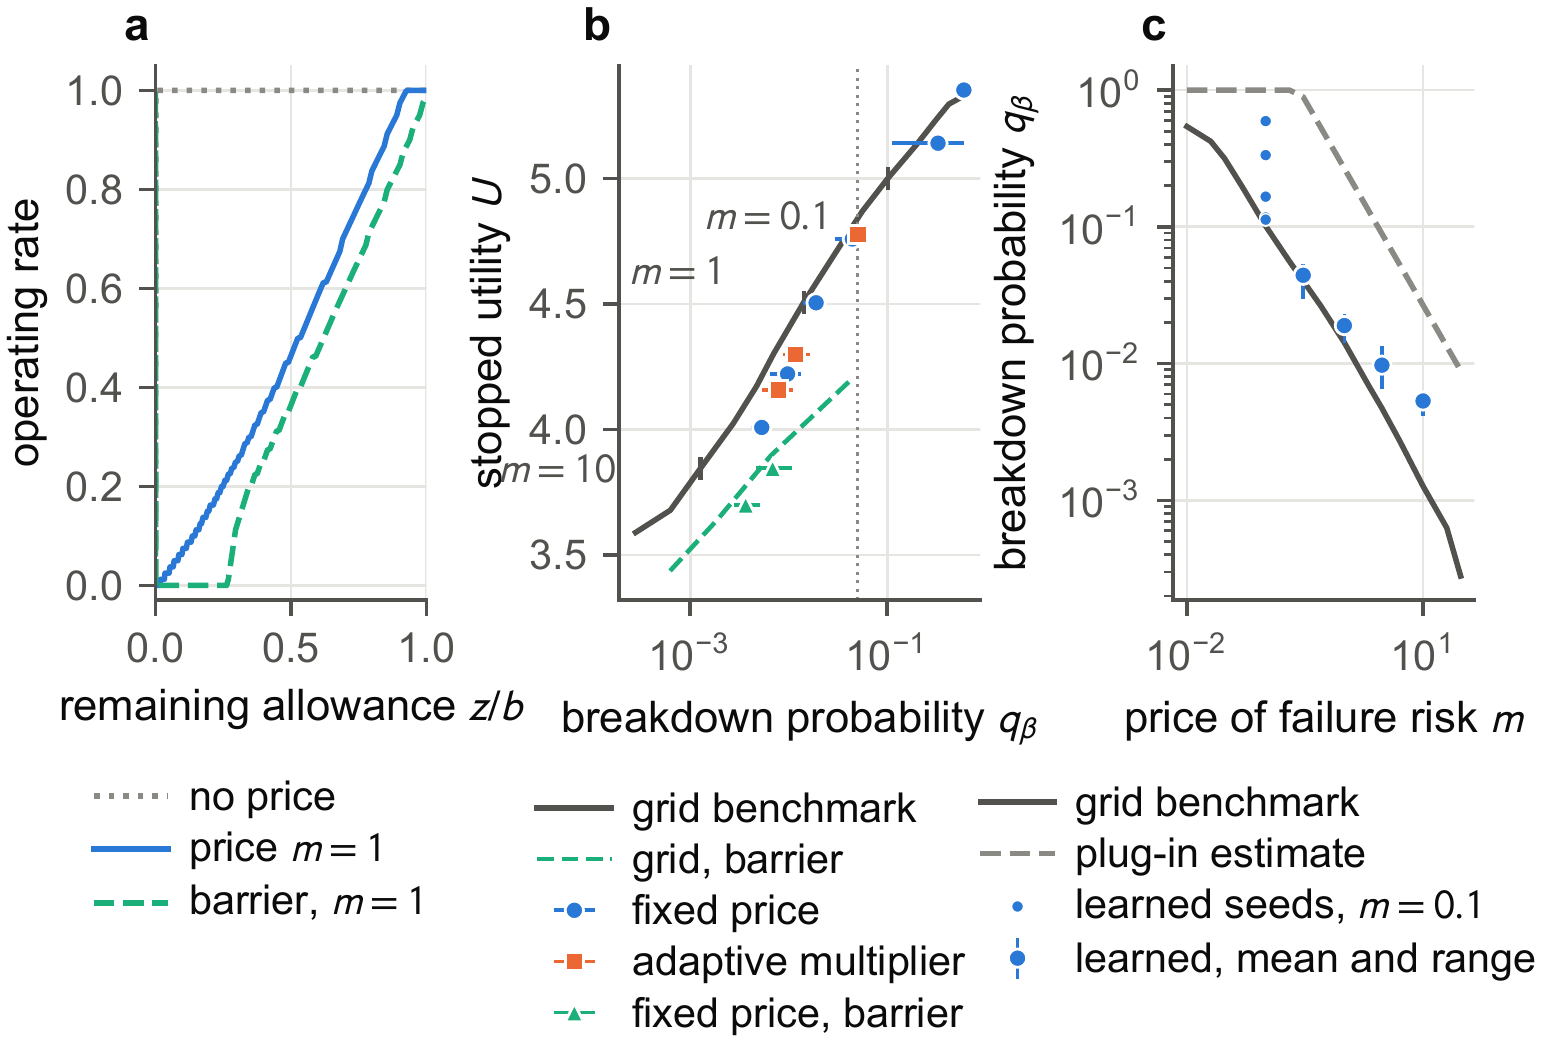

In [2]:
display(Image(filename="figures/wear-frontier.png", width=780))

Panel (a) shows the grid policies' rates as reserve changes. Panel (b) compares the utility and risk of trained configurations with both grid curves. Panel (c) shows mean breakdown probabilities and seed ranges against price, alongside a plug-in risk estimate. The latter uses benchmark quantities and the binomial tests below use the observed counts. The adaptive multiplier changes a one-time failure penalty after each rollout by a projected step proportional to observed breakdown frequency minus the training target.

In [3]:
campaign = json.loads(Path("data/wear-campaign.json").read_text())
n = campaign["evaluation_episodes"]
assert campaign["family"] == req.family
assert sum(row["seeds"] for row in campaign["configurations"].values()) == req.family
print(f"{'configuration':23s} {'mean breakdown':>14s} {'mean utility':>14s} {'validated':>11s} "
      f"{'near depletion':>14s} {'at 90% of b':>14s}")
for name, row in campaign["configurations"].items():
    failures = [round(n * q) for q in row["q"]]
    assert np.allclose(np.asarray(failures) / n, row["q"], rtol=0.0, atol=1e-12)
    trials = [validate_direct(k, n, req.alpha, req.zeta, req.family) for k in failures]
    passes = sum(result.passed for result in trials)
    assert passes == row["pass05"]
    print(f"{name:23s} {np.mean(row['q']):14.2%} {np.mean(row['U']):14.3f} "
          f"{passes:8d}/{len(trials):<2d} {row['near05']:14.2%} {row['q90']:14.2%}")

configuration           mean breakdown   mean utility   validated near depletion    at 90% of b


fixed-m0                        59.90%          5.352        0/8          61.38%         62.83%
fixed-m0.1                      32.73%          5.140        0/8          49.51%         57.18%
fixed-m0.3                       4.42%          4.759        3/8          29.43%         45.07%
fixed-m1                         1.90%          4.505        8/8          12.58%         32.65%
fixed-m3                         0.97%          4.221        8/8           3.92%         17.72%
fixed-m10                        0.53%          4.008        8/8           2.01%         11.00%
barrier-m1                       0.69%          3.845        8/8           1.02%          1.50%
barrier-m3                       0.37%          3.699        8/8           0.54%          0.87%
adaptive-a0.05-s5                5.03%          4.777        0/8          31.46%         46.25%
adaptive-a0.05-s1                5.35%          4.794        0/8          34.18%         47.36%
adaptive-a0.01-s5                1.17%  

The validation column recomputes the one-sided binomial tests with total error 0.05 across 120 policies. The next column counts episodes with minimum reserve at most $0.05b$. The last column shows breakdown under the smaller allowance. The policy still sees its nominal reserve.

The chart below compares failure-only and interior-barrier policies when the allowance is reduced. A barrier changes the reward before breakdown, which can leave more reserve as well as reduce attainable stopped utility. Compare these effects at the same price and under the same evaluation conditions.

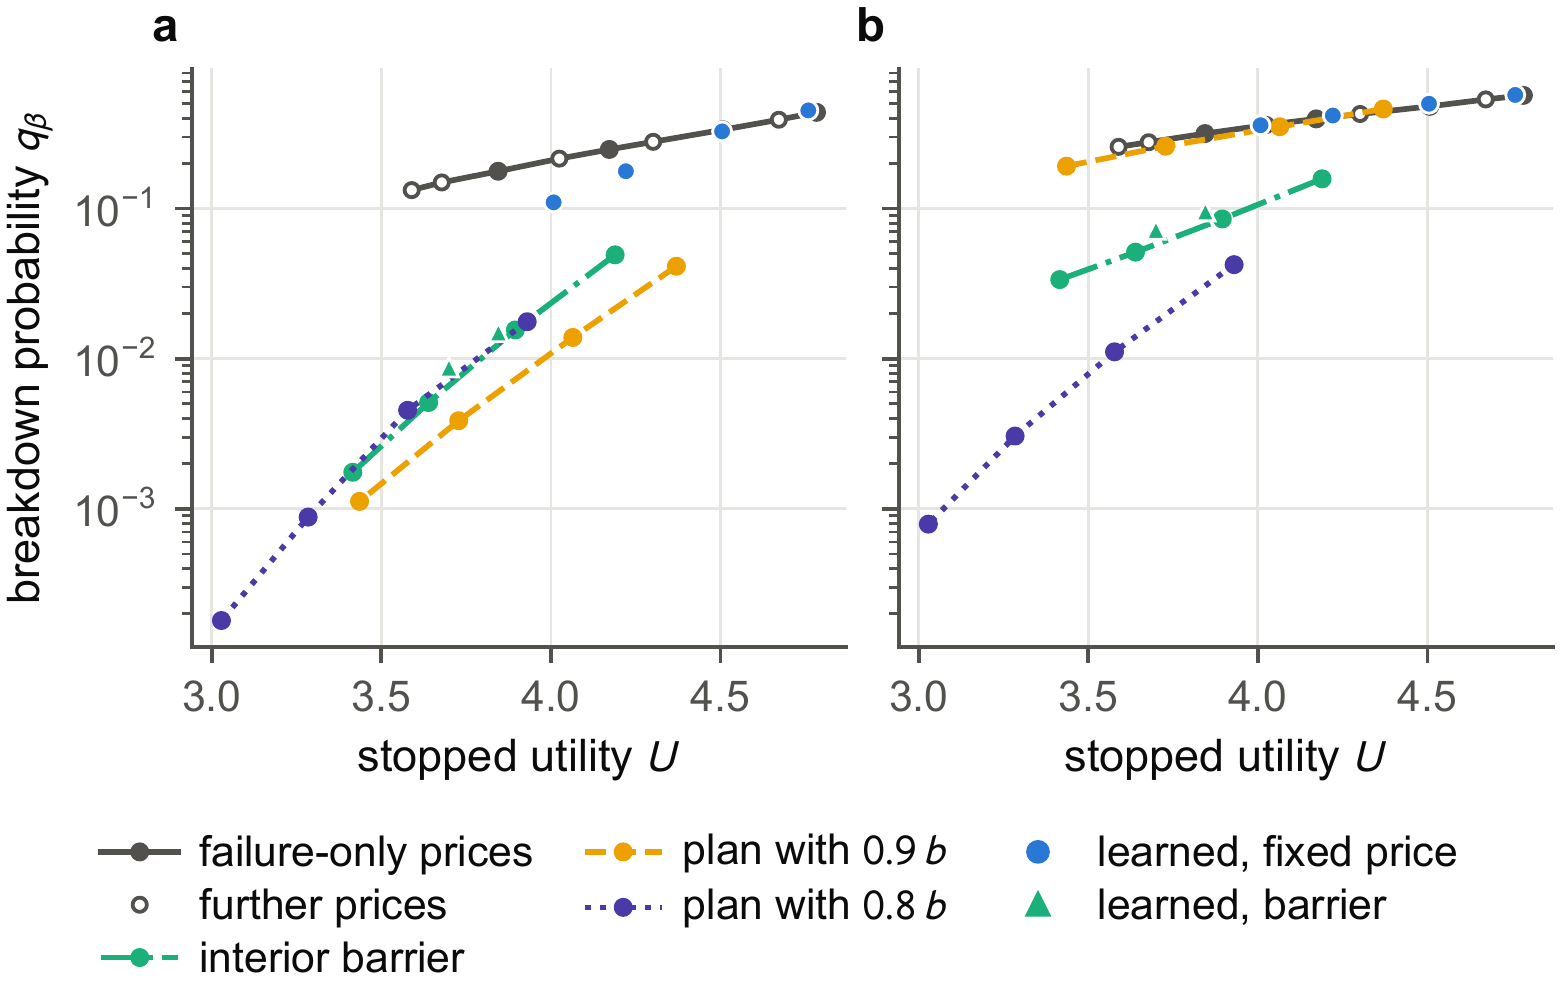

In [4]:
display(Image(filename="figures/wear-margin.png", width=780))

## Inspect the training traces

These curves show breakdown frequency during the eight-million-interaction runs. At price 0.1, some seeds stay near the no-price failure rate. In separate repeats at selected prices, the study used a constant learning rate and twice the budget. The final risk, its changes during training and its shortfall from a grid comparator answer different questions.

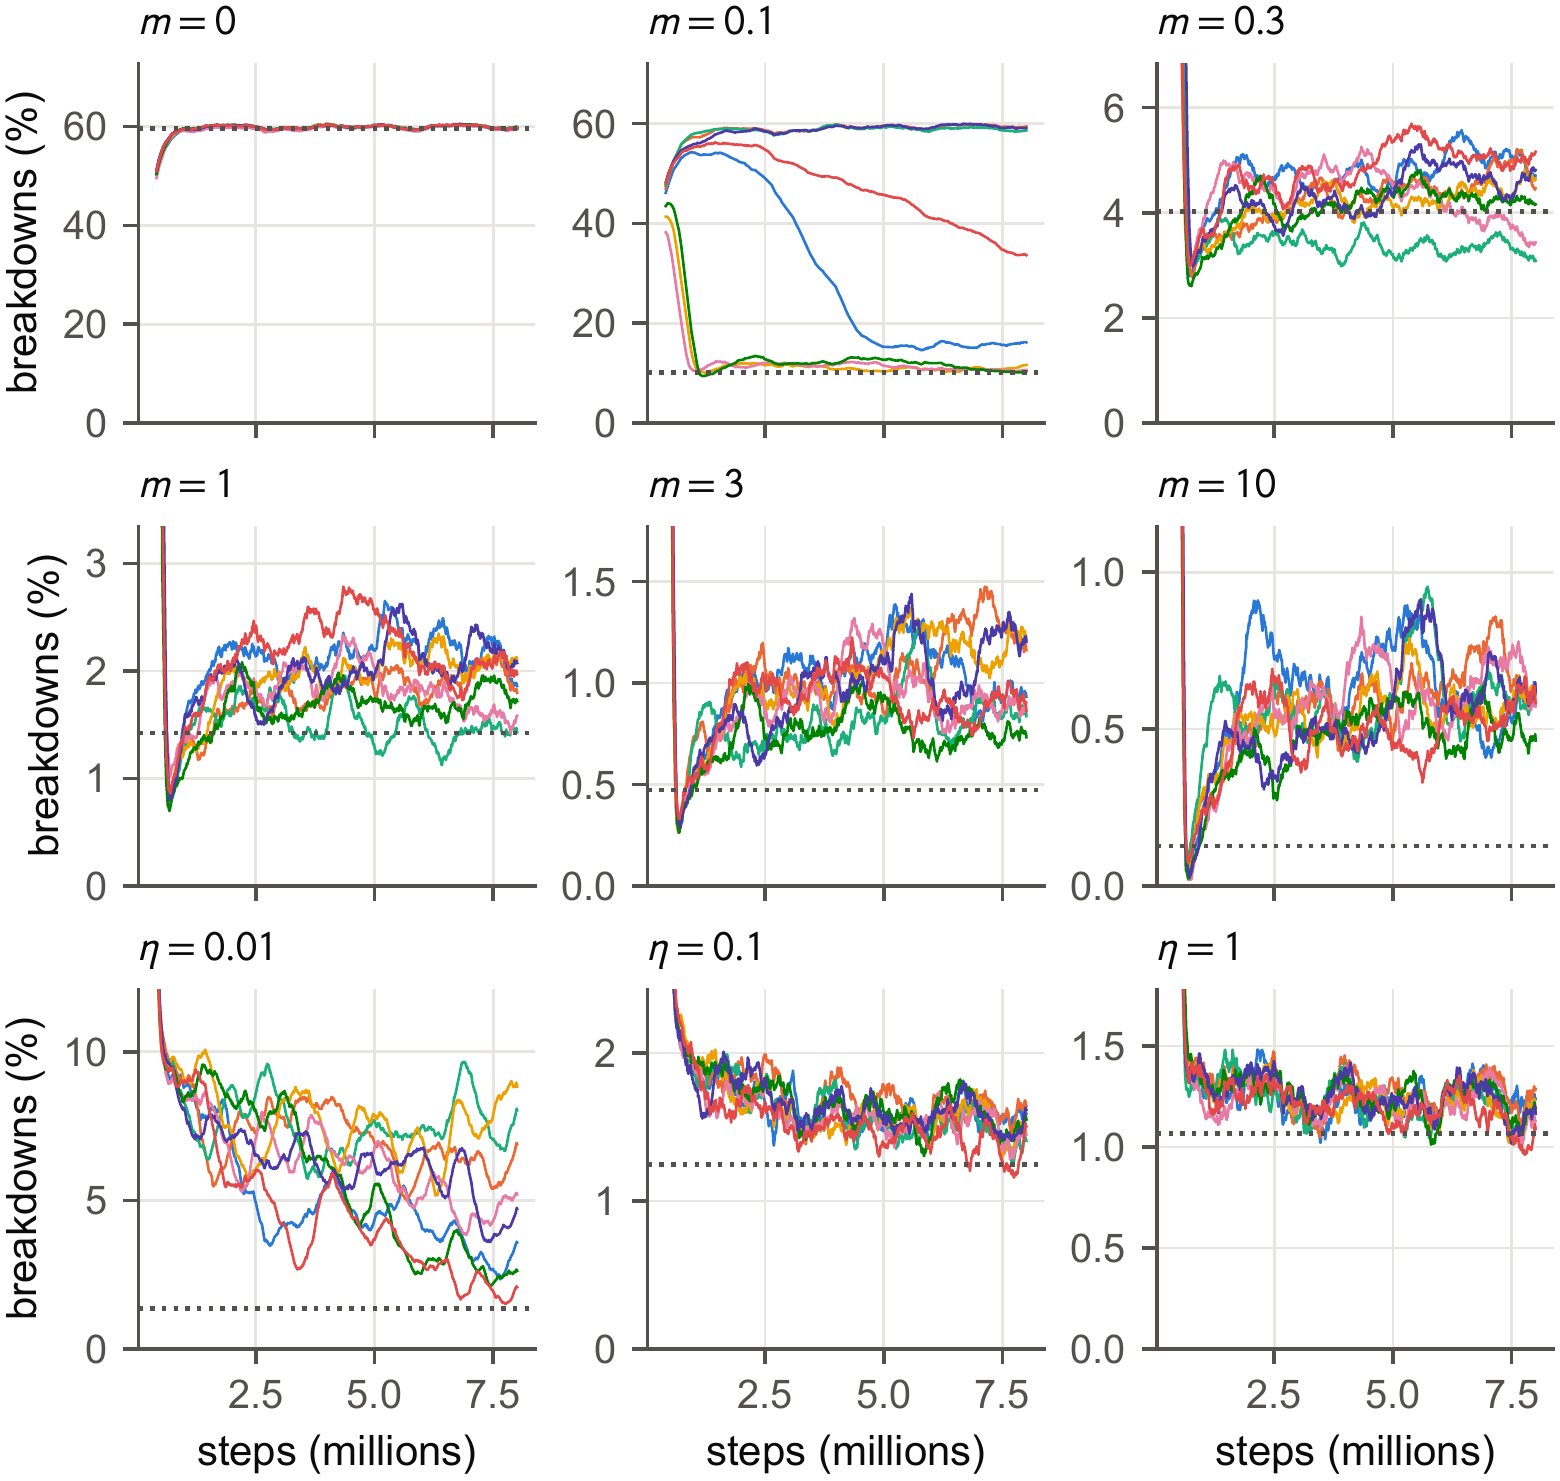

In [5]:
display(Image(filename="figures/wear-price-traces.png", width=870))

## Train and validate a policy on your simulator

The function below shows a toolbox PPO run with actions expressed directly as operating rates. The replication runner specifies the original action coordinate and campaign settings. PPO uses rollout rewards to estimate how favorable each sampled action was relative to the critic's prediction. It then updates the actor over minibatches, clipping the incentive to change the sampled action probability ratio too far from its value under the rollout policy. The critic fits returns under the same reward. The running reward scale improves numerical conditioning. Evaluate the frozen actor on fresh episodes under the stated geometric requirement.

In [6]:
def train_wear(stage, seed, steps=8_000_000, dual=None):
    from stable_baselines3 import PPO
    from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

    venv = DummyVecEnv([lambda: make_env(stage) for _ in range(32)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=1e9, gamma=1.0)
    monitor = BudgetMonitor(spec.beta, stage.m, penalty=stage.penalty, dual=dual)
    try:
        actor = PPO("MlpPolicy", venv, seed=seed, gamma=1.0, gae_lambda=0.95, n_steps=256,
                    batch_size=1024, n_epochs=10, clip_range=0.2, ent_coef=0.0,
                    learning_rate=lambda remaining: 3e-4 * remaining,
                    policy_kwargs=dict(net_arch=[64, 64], log_std_init=-1.0), device="cpu")
        actor.learn(steps, callback=[monitor] if dual is None else [dual, monitor])
    finally:
        venv.close()
    return actor, monitor


def validate_wear(actor, stage, seed, n=20_000):
    episodes = evaluate(lambda: make_env(stage), sb3_policy(actor), n, spec=spec, stage=stage, seed=seed)
    return episodes.validate(req.alpha, req.zeta, family=1)


# Fixed price: actor, trace = train_wear(stage, seed=92001)
# Validate a single fixed actor on new episodes: validate_wear(actor, stage, seed=100_000).
# Adaptive price:
# adaptive = Stage(m=0.0, penalty="multiplier", clip_utility=False)
# dual = DualAscent(alpha=0.05, step=5.0)
# actor, trace = train_wear(adaptive, seed=92001, dual=dual)
# validate_wear(actor, adaptive.with_(multiplier=dual.multiplier), seed=100_000)

The helper shows a single-policy validation. Allocate error across the full family when comparing several fitted policies. See the [run protocols and exact reproduction scripts](https://github.com/pma-papers/bpg-replication/tree/174651d8ffe7ba5a521fb06e109d8387e58c0cf9/wear-allowance) to reproduce the figures.